# JASC Code Classification: TF-IDF + Linear SVM
Classifies maintenance discrepancy text into JASC categories (first two digits of the JASC code).

## [1] Imports, paths and data loading

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)


# File paths
input_file = (
    Path.home() / "Documents" / "AIE410_Project"
    / "Data_Preprocessed" / "Data_output.parquet"
)

output_file = (Path.home() / "Documents" / "AIE410_Project" / "SVM_TFIDF" )

model_file = output_file / "jasc_linear_svm.joblib"
report_file = output_file / "jasc_svm_classification_report.csv"
predictions_file = output_file / "jasc_svm_test_predictions.csv"
confusion_matrix_file = output_file / "jasc_svm_confusion_matrix.png"

if not input_file.exists():
    raise FileNotFoundError(f"File not found: {input_file}")

df = pd.read_parquet(input_file)

required_columns = ["JASCCode", "Discrepancy"]
missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

print("Dataset shape:", df.shape)
display(df.head())

## [2] Environment setup for secure HTTPS and NLTK downloads

This code configures secure HTTPS certificate verification using the certifi certificate bundle, then imports NLTK tools for text preprocessing. It downloads the required language datasets (stopwords, wordnet, and omw-1.4) for tasks such as removing common words, stemming, and lemmatizing text.

In [ ]:
import os
import ssl
import certifi

os.environ["SSL_CERT_FILE"] = certifi.where()
os.environ["REQUESTS_CA_BUNDLE"] = certifi.where()
ssl._create_default_https_context = ssl.create_default_context
print("Certificate bundle:", certifi.where())

import re
import nltk
from functools import lru_cache
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer, PorterStemmer

# One-time downloads (safe to re-run)
for pkg in ["stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)

Certificate bundle: /Users/nileshsaumyadasa/Documents/AIE410_Project/.venv/lib/python3.14/site-packages/certifi/cacert.pem


## [3] Text cleaning and preprocessing

In [7]:
# Set the number of records to use; None means use all available data
SAMPLE_SIZE = 1000
# Set a fixed random seed so sampling and shuffling are reproducible
RANDOM_STATE = 42
# Choose how words are normalized: "lemma", "stem", or None
NORMALIZATION = "lemma"

# Load common English stop words, but keep negations because they are important
# for fault descriptions, such as "no leak", "not working", and "without damage"
STOP_WORDS = set(stopwords.words("english")) - {"no", "not", "nor", "without"}

# Select the word normalization method based on the NORMALIZATION setting
# Lemmatization converts words to their base forms; stemming removes word endings
# If None or an unrecognized option is provided, words remain unchanged
_norm = {
    "lemma": WordNetLemmatizer().lemmatize,
    "stem": PorterStemmer().stem
}.get(NORMALIZATION, lambda t: t)

# Cache previously normalized words to avoid processing repeated words again
_norm = lru_cache(maxsize=None)(_norm)

def preprocess_text(text):
    # Convert text to lowercase and replace punctuation and special characters
    # with spaces, then split the text into individual words
    tokens = re.sub(r"[\W_]+", " ", str(text).lower()).split()

    # Remove stop words, normalize the remaining words, and join them into
    # a single cleaned text string
    return " ".join(_norm(t) for t in tokens if t not in STOP_WORDS)


# Select the discrepancy descriptions and JASC codes for processing
data = df[["Discrepancy", "JASCCode"]].copy()

# Remove leading and trailing whitespace from discrepancy descriptions
data["Discrepancy"] = data["Discrepancy"].astype("string").str.strip()

# Convert JASC codes to numbers; invalid values become missing values
data["JASCCode"] = pd.to_numeric(data["JASCCode"], errors="coerce")

# Remove rows with missing values
data = data.dropna()

# Keep only non-empty descriptions and valid JASC codes that are
# non-negative whole numbers
data = data[
    (data["Discrepancy"] != "")
    & (data["JASCCode"] >= 0)
    & (data["JASCCode"] % 1 == 0)
]

# Create a broader JASC category using the first two digits of each code
# Example: JASC code 3210 becomes category "32"
data["JASC_Category"] = (
    data["JASCCode"].astype("int64").astype(str).str[:2]
)

# If a sample size is specified and the dataset is larger than that size,
# randomly select the specified number of records to reduce processing time
if SAMPLE_SIZE and len(data) > SAMPLE_SIZE:
    data = data.sample(SAMPLE_SIZE, random_state=RANDOM_STATE)

# Apply text preprocessing to each discrepancy description and save the
# cleaned result in a new column called Clean_Text
data["Clean_Text"] = data["Discrepancy"].map(preprocess_text)

# Remove descriptions that become empty after preprocessing
# Remove duplicate combinations of cleaned text and JASC category
# Shuffle the records and reset the row index
data = (
    data[data["Clean_Text"] != ""]
    .drop_duplicates(["Clean_Text", "JASC_Category"])
    .sample(frac=1, random_state=RANDOM_STATE)
    .reset_index(drop=True)
)

# X contains the cleaned descriptions used as model inputs
# y contains the JASC categories the model will learn to predict
X, y = data["Clean_Text"], data["JASC_Category"]

# Print the total number of records and unique JASC categories
print(f"Samples: {len(data):,} | Categories: {y.nunique():,}")

# Display the number of records in each JASC category
display(
    y.value_counts()
    .sort_index()
    .rename("SampleCount")
    .to_frame()
)

# Display a preview of the original descriptions, cleaned text,
# and corresponding JASC categories
display(data[["Discrepancy", "Clean_Text", "JASC_Category"]].head())


Samples: 999 | Categories: 43


,SampleCount
JASC_Category,
21,31
22,1
23,3
24,13
25,46
26,11
27,22
28,9
29,11


,Discrepancy,Clean_Text,JASC_Category
0,"DURING INSPECTION, A CRACK WAS FOUND ON THE SH...",inspection crack found shear clip frame 73 str...,53
1,INSPECTION TYPE-C M/D BS 820 LT SIDE TENSION T...,inspection type c b 820 lt side tension tie fr...,53
2,"FLT#872, SLC-JFK. 'STRONG DIRTY SOCK ODOR DURI...",flt 872 slc jfk strong dirty sock odor decent ...,21
3,FWD CARGO BS 780 TO 800 STR 28R CORRODED. COR...,fwd cargo b 780 800 str 28r corroded corroded ...,53
4,PITOT 3 INOP DISPLAYED ON EICAS AROUND 10K FEE...,pitot 3 inop displayed eicas around 10k foot p...,34


## [4] Split into training and testing datasets

In [15]:
# Count how many samples belong to each JASC category
class_counts = y.value_counts()

# Count the total number of unique JASC categories
n_classes = y.nunique()

# Ensure there are enough samples to create training and testing datasets
if len(data) < 4:
    raise ValueError("Select at least 4 samples for a train/test split.")

# Ensure there are at least two categories for the model to classify
if n_classes < 2:
    raise ValueError("At least 2 distinct JASC categories are required.")

# Calculate the number of samples for testing (20%), rounding up
n_test = int(np.ceil(0.20 * len(data)))

# Assign the remaining 80% of samples to training
n_train = len(data) - n_test

# Check whether stratified splitting is possible.
# Each category must have at least 2 samples, and both datasets must
# have enough space to include every category.
can_stratify = (
    class_counts.min() >= 2
    and n_test >= n_classes
    and n_train >= n_classes
)

# Split the data into training and testing sets.
# Training data is used to teach the model, while testing data evaluates
# how well the model predicts categories on unseen descriptions.
# Stratification preserves category proportions when the data allows it.
# RANDOM_STATE ensures the split is reproducible.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y if can_stratify else None,
)

# Display the number of samples assigned to the training dataset
print(f"Training samples: {len(X_train):,}")

# Display the number of samples assigned to the testing dataset
print(f"Testing samples:  {len(X_test):,}")

# Display how many unique JASC categories appear in the training dataset
print(f"Training classes: {y_train.nunique():,}")

# Show whether stratified splitting was used
print(f"Stratified split: {can_stratify}")


Training samples: 1,364,976
Testing samples:  341,244
Training classes: 51
Stratified split: True


## [5] Create and train the TF-IDF + Linear SVM pipeline

In [16]:
# Create a machine learning pipeline that combines text processing
# with a classifier to predict JASC categories from discrepancy descriptions
model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,           # Convert all text to lowercase
            strip_accents="unicode",  # Remove accent marks from characters
            ngram_range=(1, 2),       # Use single words and two-word combinations
            max_features=80000,       # Keep at most 80,000 text features
            sublinear_tf=True,        # Reduce the influence of frequently repeated words
            min_df=2,                 # Ignore words or phrases appearing in fewer than 2 documents
            dtype=np.float64,         # Store TF-IDF values as 64-bit floating-point numbers
        ),
    ),
    (
        "classifier",
        LinearSVC(
            C=1.0,                    # Set the regularization strength.. controls model complexity
            class_weight="balanced",  # Give more weight to categories with fewer samples
            loss="squared_hinge",     # Use squared hinge loss to learn classification boundaries
            dual="auto",              # Automatically choose the most suitable optimization approach
            max_iter=5000,            # Allow up to 5,000 training iterations
            tol=1e-4,                 # Set the tolerance for determining convergence
            random_state=RANDOM_STATE, # Set the random seed for reproducibility where applicable
        ),
    ),
])

# Train the pipeline using the training descriptions and their JASC categories.
# TF-IDF converts text into numerical features, and LinearSVC learns
# to classify those features into the appropriate JASC categories.
print("Training TF-IDF + Linear SVM...")
model.fit(X_train, y_train)

# Confirm that training has finished
print("Training completed.")

# Display the number of text features created by the TF-IDF vectorizer
print("TF-IDF features:", len(model.named_steps["tfidf"].vocabulary_))

# Display the number of distinct JASC categories learned by the classifier
print("Classes learned:", len(model.named_steps["classifier"].classes_))


Training TF-IDF + Linear SVM...
Training completed.
TF-IDF features: 80000
Classes learned: 51


## [6] Evaluate model performance

In [17]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)
weighted_f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

print(f"Accuracy:    {accuracy:.4f}")
print(f"Macro F1:    {macro_f1:.4f}")
print(f"Weighted F1: {weighted_f1:.4f}")

print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy:    0.9190
Macro F1:    0.7081
Weighted F1: 0.9199

Classification report:
              precision    recall  f1-score   support

          11       0.81      0.85      0.83       219
          12       0.00      0.00      0.00         5
          14       0.36      0.24      0.29       196
          18       0.33      0.50      0.40         2
          21       0.89      0.90      0.89      9405
          22       0.75      0.80      0.77      1410
          23       0.83      0.87      0.85      1554
          24       0.82      0.85      0.83      3817
          25       0.88      0.87      0.88     14830
          26       0.90      0.94      0.92      4105
          27       0.89      0.88      0.88      8377
          28       0.82      0.87      0.84      3214
          29       0.86      0.89      0.87      3695
          30       0.78      0.80      0.79      2006
          31       0.45      0.45      0.45      1423
          32       0.92      0.93      0.93     125

## [7] Save model, report, predictions and confusion matrix

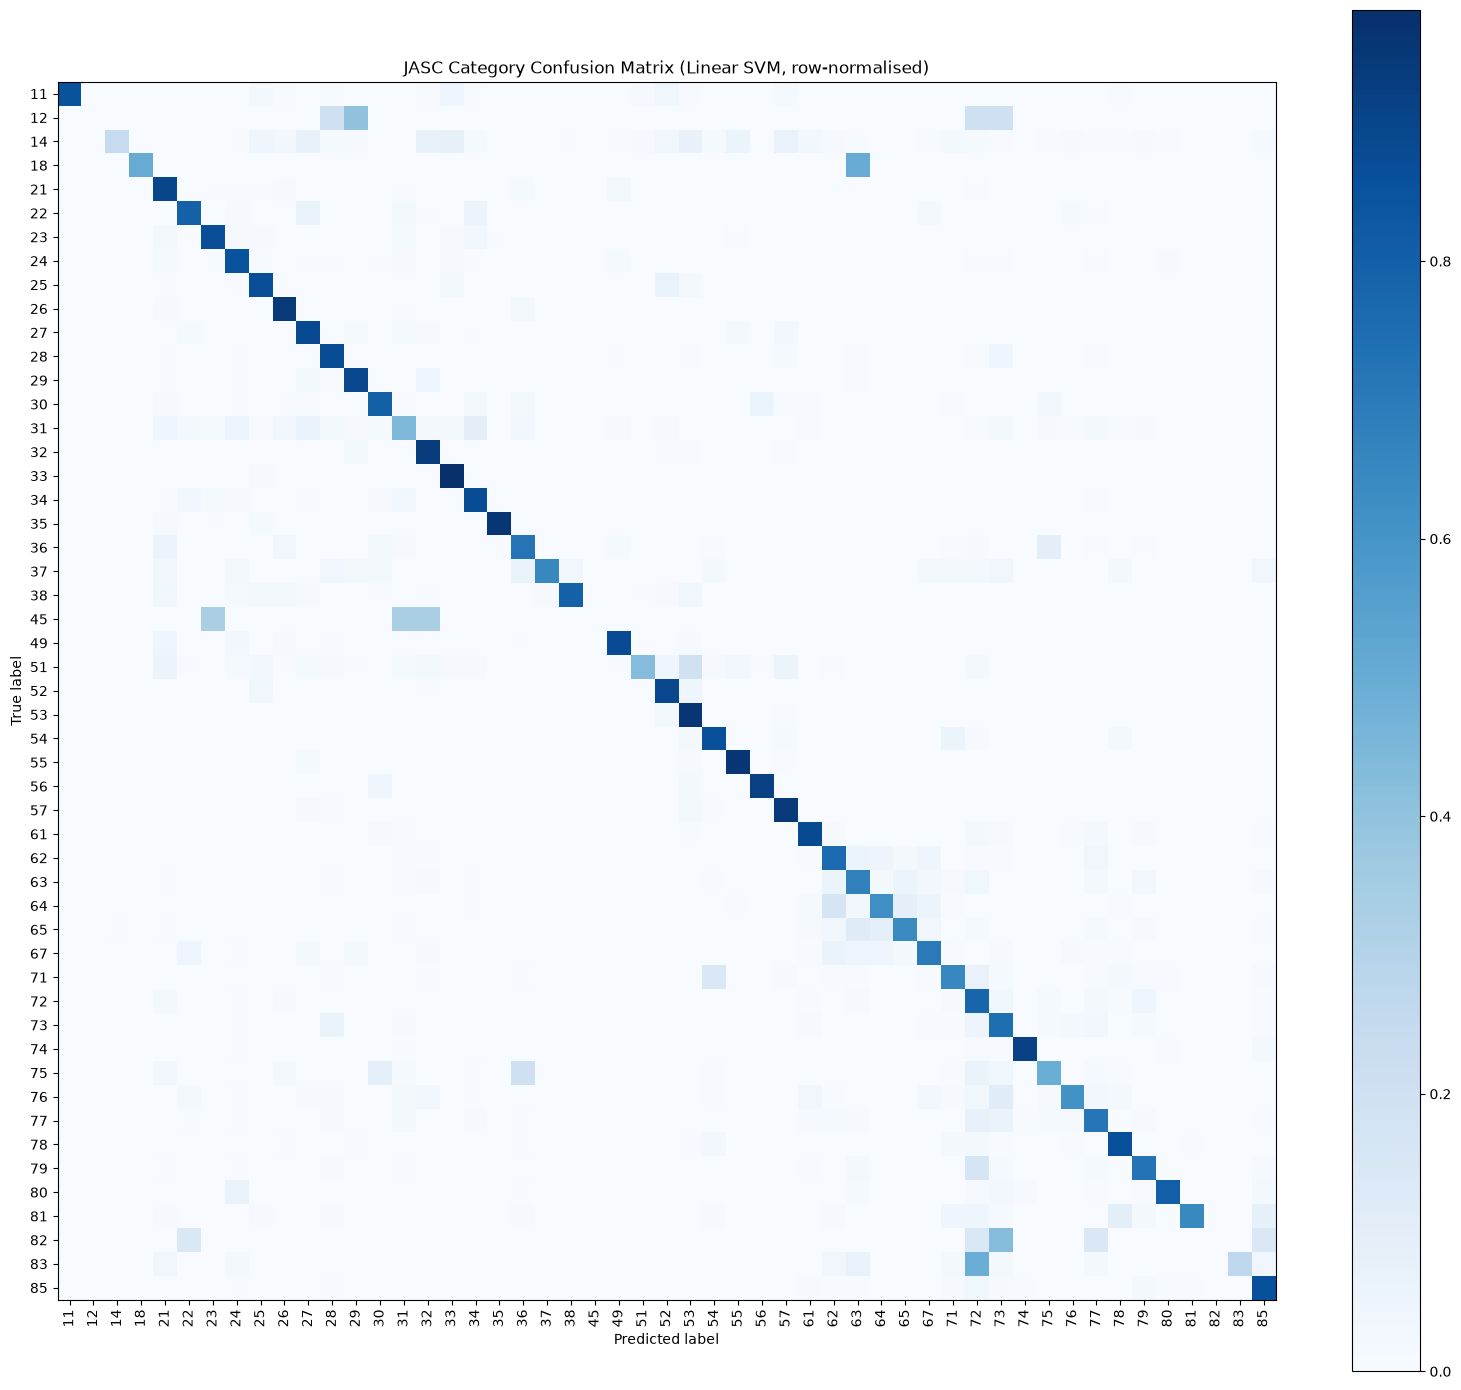

Saved:
 - /Users/nileshsaumyadasa/Documents/AIE410_Project/SVM_TFIDF/jasc_linear_svm.joblib
 - /Users/nileshsaumyadasa/Documents/AIE410_Project/SVM_TFIDF/jasc_svm_classification_report.csv
 - /Users/nileshsaumyadasa/Documents/AIE410_Project/SVM_TFIDF/jasc_svm_test_predictions.csv
 - /Users/nileshsaumyadasa/Documents/AIE410_Project/SVM_TFIDF/jasc_svm_confusion_matrix.png


In [18]:
# Classification report
report_df = pd.DataFrame(
    classification_report(y_test, y_pred, zero_division=0, output_dict=True)
).T
report_df.to_csv(report_file)

# Test predictions with SVM decision margin (confidence proxy)
scores = model.decision_function(X_test)
top_score = scores.max(axis=1) if scores.ndim > 1 else np.abs(scores)

pred_df = pd.DataFrame({
    "Clean_Text": X_test.values,
    "True_JASC_Category": y_test.values,
    "Predicted_JASC_Category": y_pred,
    "Decision_Score": top_score,
})
pred_df.to_csv(predictions_file, index=False)

# Confusion matrix (row-normalised so large classes don't dominate)
fig, ax = plt.subplots(figsize=(16, 14))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    normalize="true",
    include_values=False,
    xticks_rotation=90,
    cmap="Blues",
    ax=ax,
)
ax.set_title("JASC Category Confusion Matrix (Linear SVM, row-normalised)")
plt.tight_layout()
fig.savefig(confusion_matrix_file, dpi=200)
plt.show()

# Model
joblib.dump(model, model_file)

print("Saved:")
for p in [model_file, report_file, predictions_file, confusion_matrix_file]:
    print(" -", p)

## [8] Predict on new text

In [49]:
example_text = ["HYD SYS B LOW PRESS fault logged but pump, reservoir and lines all check good, no leaks. Replaced central maintenance computer, fault correlation now correct."]

# Apply the same preprocessing used for training
example_clean = [preprocess_text(t) for t in example_text]

predicted = model.predict(example_clean)
scores = model.decision_function(example_clean)[0]

print("Predicted JASC category:", predicted[0])

# Top 5 candidate categories by SVM margin
top5 = np.argsort(scores)[::-1][:5]
classes = model.named_steps["classifier"].classes_
for i in top5:
    print(f"  {classes[i]}  score={scores[i]:.3f}")

Predicted JASC category: 29
  29  score=1.432
  31  score=-0.897
  77  score=-0.965
  45  score=-1.086
  25  score=-1.361


In [24]:
import os
import joblib
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Path to your saved machine learning model
model_path = "/Users/nileshsaumyadasa/Documents/AIE410_Project/SVM_TFIDF/jasc_linear_svm.joblib"

# Load the trained model
model = joblib.load(model_path)

print("Model loaded successfully!")

# Example maintenance text
example_text = [
    "Oil residue observed around engine oil filter housing during post-flight inspection"
]

# Apply the same preprocessing used during training
example_clean = [preprocess_text(t) for t in example_text]

# Predict the JASC category
predicted = model.predict(example_clean)

# Get SVM decision scores
scores = model.decision_function(example_clean)[0]

print("\nPredicted JASC category:", predicted[0])

# Display top 5 candidate categories by SVM margin
top5 = np.argsort(scores)[::-1][:5]

# Get the class labels from the trained classifier
classes = model.named_steps["classifier"].classes_

print("\nTop 5 candidate JASC categories:")
for i in top5:
    print(f"  {classes[i]}  score={scores[i]:.3f}")

Model loaded successfully!

Predicted JASC category: 72

Top 5 candidate JASC categories:
  72  score=0.508
  85  score=-0.402
  79  score=-0.497
  63  score=-1.138
  54  score=-1.149
